In [6]:
import kdsource.api as kds
import numpy as np

In [4]:
help(kds.write_mcpl)

Help on function write_mcpl in module kdsource.writemcpl:

write_mcpl(filename, *, ekin, x, y, z, ux, uy, uz, time, weight, pdgcode, polx=None, poly=None, polz=None, userflags=None, double_prec=False, force=False)
    Create MCPL file in the path indicated, based on particle data in numpy
    arrays. The arrays must of course all have equal length, with the exception
    that weight and pdgcode parameters are allowed to have a single scalar
    value, representing a fixed value of all particules. Additionally, polx,
    poly, polz, and userflags can be None to leave such field out of the
    file. The double_prec flag can be used to enable double precision storage of
    floating point values, and the force flag allows overwriting existing files.

    Note that the extension of the produced file will always end up as .mcpl.gz,
    so it is least surprising if the provided filename already has such an
    extension.



In [ ]:
file_path = "my_data.mcpl.gz"

empty_10 = np.zeros(10)
full_10 = np.ones(10)
kds.write_mcpl(filename=file_path, ekin=full_10, x=empty_10, y=empty_10, z=empty_10, ux=full_10, uy=empty_10, uz=empty_10, time=empty_10, weight=full_10, pdgcode=2112)

MCPL: Compressing file data.mcpl
MCPL: Compressed file into data.mcpl.gz


In [12]:
import mcpl
import pandas as pd

myfile=mcpl.MCPLFile(file_path,blocklength=2)
datas = []
for i,p in enumerate(myfile.particle_blocks):
    print("block no.", i)
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

block no. 0
block no. 1
block no. 2
block no. 3
block no. 4


,Kf,x,y,z,Vx,Vy,Vz,e,Wt
0,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
1,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
2,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
3,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
4,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
5,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
6,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
7,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
8,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
9,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0


In [14]:
data.dtypes

Kf      int64
x     float32
y     float32
z     float32
Vx    float64
Vy    float64
Vz    float64
e     float64
Wt    float64
dtype: object

In [15]:
myfile=mcpl.MCPLFile("./examples/uniform/output.mcpl.gz",blocklength=100)
datas = []
for i,p in enumerate(myfile.particle_blocks):
    if i==1: break
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

,Kf,x,y,z,Vx,Vy,Vz,e,Wt
0,2112,-0.162481,-0.040676,0.06,-0.660523,0.190048,0.726355,2.500000e-08,1.0
1,2112,-0.029267,-0.583007,0.06,-0.547038,-0.737882,0.395322,2.500000e-08,1.0
2,2112,0.011129,0.043405,0.06,-0.497699,0.456605,0.737433,2.500000e-08,1.0
3,2112,0.215334,0.099948,0.06,0.123330,0.753316,0.645991,2.500000e-08,1.0
4,2112,0.276657,-0.141431,0.06,0.950695,0.016866,0.309668,2.500000e-08,1.0
...,...,...,...,...,...,...,...,...,...
95,2112,-0.164676,0.330439,0.06,0.379884,0.696097,0.609210,2.500000e-08,1.0
96,2112,-0.096169,0.080179,0.06,-0.122769,0.956632,0.264165,2.500000e-08,1.0
97,2112,-0.098242,-0.198568,0.06,-0.471250,0.169412,0.865577,2.500000e-08,1.0
98,2112,-0.335520,-0.083919,0.06,0.288980,-0.109987,0.950996,2.500000e-08,1.0


In [16]:
kds.write_mcpl(filename=file_path, ekin=data["e"], x=data["x"], y=data["y"], z=data["z"],
                ux=data["Vx"], uy=data["Vy"], uz=data["Vz"], time=np.zeros_like(data["Kf"]), weight=data["Wt"], pdgcode=data["Kf"])

MCPL: Compressing file data.mcpl
MCPL: Compressed file into data.mcpl.gz


In [1]:
import kdsource.api as kds  # Importing the KDSource Python API

In [2]:
kds.Geometry?

Init signature: kds.Geometry(metrics, trasl=None, rot=None)
Docstring:      <no docstring>
Init docstring:
Object defining particle variables treatment (metrics).

The main function of a Geometry is definig a transformation from
particle variables to certain parametrized variables, which can
be more suitable for applying KDE.

Parameters
----------
metrics: list
    List of metrics for each subset of variables. They must
    cover all particle variables (energy, position,
    direction and time).
trasl: array-like, optional
    Spatial traslation for source. Default is no traslation.
rot: numpy.ndarray or scipy.spatial.transform.Rotation, optional
    Spatial rotation for source. Can be a scipy Rotation object,
    or any array-like which can be used to generate a scipy
    Rotation object (rotation vector, quaternion or rotation
    matrix). Rotation is applied after traslation in transform,
    and before traslation in inverse_transform. Default is no
    rotation.
File:           ~/

In [3]:
kds.Metric?

Init signature: kds.Metric(partvars, varnames, units, volunits)
Docstring:      <no docstring>
Init docstring:
Abstract object defining metrics for a subset of variables.

The main function of a Metric is definig a transformation from a
subset of particle variables to certain parametrized variables,
which can be more suitable for applying KDE.

See geom._metrics for available metrics.

Parameters
----------
partvars: list of int
    Indices of the particle variables to parametrize (see
    varnames global list).
varnames: list of str
    Names of parametrized variables.
units: list of str
    Units of each parametrized variable.
volunits: str
    Units of the product of variables to parametrize.
File:           ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/geom.py
Type:           type
Subclasses:     Geometry, Energy, Lethargy, Wavelength, Time, Decade, Vol, SurfXY, SurfR, SurfR2, ...

In [4]:
kds.geom._metrics

{'Energy': kdsource.geom.Energy,
 'Lethargy': kdsource.geom.Lethargy,
 'Wavelength': kdsource.geom.Wavelength,
 'Vol': kdsource.geom.Vol,
 'SurfXY': kdsource.geom.SurfXY,
 'SurfR': kdsource.geom.SurfR,
 'SurfR2': kdsource.geom.SurfR2,
 'SurfCircle': kdsource.geom.SurfCircle,
 'Guide': kdsource.geom.Guide,
 'Isotrop': kdsource.geom.Isotrop,
 'Polar': kdsource.geom.Polar,
 'PolarMu': kdsource.geom.PolarMu,
 'Time': kdsource.geom.Time,
 'Decade': kdsource.geom.Decade}

In [5]:
my_energy = kds.geom.Energy()
#my_lethargy = kds.geom.Lethargy()

In [6]:
type(my_energy)

kdsource.geom.Energy

In [7]:
for k,v in my_energy.__dict__.items():
    print(k, str(v))

partvars [0]
dim 1
varnames ['ekin']
varmap {'ekin': 0}
units ['MeV']
volunits MeV


In [8]:
# for k,v in my_lethargy.__dict__.items():
#     print(k, str(v))

In [9]:
my_position = kds.geom.Vol()
my_time = kds.geom.Time()
my_directions = kds.geom.Isotrop()

In [10]:
my_geometry = kds.Geometry([
    my_energy, my_time, my_position, my_directions
])

In [11]:
for k,v in my_geometry.__dict__.items():
    print(k, str(v))

partvars range(0, 8)
dim 8
varnames ['ekin', 't', 'x', 'y', 'z', 'dx', 'dy', 'dz']
varmap {'ekin': 0, 't': 1, 'x': 2, 'y': 3, 'z': 4, 'dx': 5, 'dy': 6, 'dz': 7}
units ['MeV', 'ms', 'cm', 'cm', 'cm', '[dir]', '[dir]', '[dir]']
volunits MeV ms cm^3 [dir]^3
ms [<kdsource.geom.Energy object at 0x7e30b1d74a40>, <kdsource.geom.Time object at 0x7e30553fd850>, <kdsource.geom.Vol object at 0x7e30553ff8c0>, <kdsource.geom.Isotrop object at 0x7e3054d131a0>]
trasl None
rot None


In [12]:
kds.KDSource?

Init signature: kds.KDSource(plist, geom, bw='auto', J=1.0, kernel='gaussian')
Docstring:      <no docstring>
Init docstring:
Object representing Kernel Density Estimation (KDE) sources.

A KDSource object is based on a particle list in MCPL format,
wrapped in a PList object. It also includes a Geometry object,
which defines variables (energy, position, direction) treatment.
Having these basic components, KDSource can fit (optimize) a KDE
model on the particle list, creating a distributional source.

After optimization, analysis, plotting, etc., a KDSource can be
exported in XML format, for later use in Python or other
KDSource tools.

Parameters
----------
plist: PList object
    The PList wrapping the MCPL file containing the particle
    list.
geom: Geometry object
    The Geometry defining particle variables treatment.
bw: float, str or numpy.ndarray, optional
    Bandwidth or bandwidth selection method for KDE. If a float
    is passed, it is the bandwidth for all particles. If a


In [13]:
import kdsource

In [14]:
kdsource?

Type:        module
String form: <module 'kdsource' from '/home/jhonal/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/__init__.py'>
File:        ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/__init__.py
Docstring:  
Python module for creating and optimizing KDSource objects.

KDSource's are particle sources for Monte Carlo radiation transport
simulations. The full distribution and documentation can be found in the
project GitHub page:

    https://github.com/KDSource/KDSource

A KDSource object is based on a particle list in MCPL format (see
https://mctools.github.io/mcpl/), on which a Kernel Density Estimation
(KDE) is applied, using KDEpy library (see
https://github.com/tommyod/KDEpy).

With kdsource Python library you can create, optimize, and export
KDSource objects as XML files. These files can be later used as
distributional sources in other Monte Carlo simulations, using the tools
available in the full distribution.

If you use KD

In [15]:
kds.kde.bw_methods

{'auto': <function kdsource.kde.bw_auto(data, weights, grid=None, Nmlcv=10000.0, Nbatch=10000.0, Nknn=10, show=True, n_splits=10)>,
 'silv': <function kdsource.kde.bw_silv(dim, N_eff)>,
 'knn': <function kdsource.kde.bw_knn(data, weights=None, K_eff=100, k=None, batch_size=10000)>,
 'mlcv': <function kdsource.kde.bw_mlcv(data, weights=None, n_splits=10, seed=None, grid=None, show=True)>}

In [16]:
# Step 1: Load your original MCPL particle track list file
my_input_file_path = "./examples/uniform/output.mcpl.gz"

my_input_plist = kds.PList(filename=my_input_file_path,
                           readformat="mcpl",
                           pt="n",
                           trasl=None,
                           rot=None,
                           switch_x2z=False,
                           set_params=True)


Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0


In [17]:
vars(my_input_plist)

{'filename': './examples/uniform/output.mcpl.gz',
 'pt': 'n',
 'trasl': None,
 'rot': None,
 'x2z': False,
 'params_set': True,
 'sum_weights': np.float64(21580959.0),
 'p2': np.float64(21580959.0),
 'N': 21580959,
 'N_eff': np.float64(21580959.0)}

In [21]:
my_source.fitted

False

In [ ]:
my_source = kds.KDSource(
    plist=my_input_plist, geom=my_geometry, bw="mlcv", J=1.0, kernel="gaussian"
)

In [31]:
my_source.fitted

False

In [32]:
[attr for attr in dir(my_source) if attr[0:2]!="__"]

['J',
 'R',
 'bw_method',
 'evaluate',
 'fit',
 'fitted',
 'geom',
 'kde',
 'kernel',
 'plist',
 'plot2D_integr',
 'plot2D_point',
 'plot_E',
 'plot_integr',
 'plot_point',
 'plot_t',
 'save',
 'scaling']

In [33]:
vars(my_source.plist)

{'filename': './examples/uniform/output.mcpl.gz',
 'pt': 'n',
 'trasl': None,
 'rot': None,
 'x2z': False,
 'params_set': True,
 'sum_weights': np.float64(21580959.0),
 'p2': np.float64(21580959.0),
 'N': 21580959,
 'N_eff': np.float64(21580959.0)}

In [34]:
my_source.fitted, my_source.bw_method

(False, 'mlcv')

Using 10000 particles for fit.
Calculating bw ... 
No grid specified. Using np.logspace(-0.1, 0.1, 10).
If fitting fails, change the grid.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=-1)]: Done   3 out of  10 | elapsed:   22.3s remaining:   51.9s
[Parallel(n_jobs=-1)]: Done   5 out of  10 | elapsed:   22.8s remaining:   22.8s
[Parallel(n_jobs=-1)]: Done   7 out of  10 | elapsed:   23.8s remaining:   10.2s
[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   30.3s finished


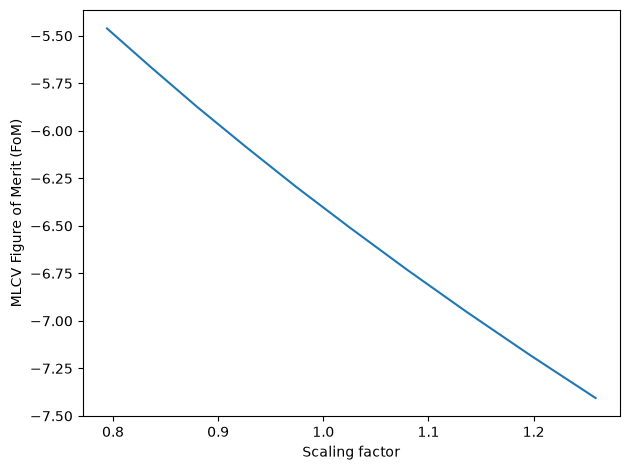

Exception: Maximum not found in bw range selected. Move grid and try again.

In [ ]:
my_source.fit(N=10000)

In [41]:
vars(my_source.geom)

{'partvars': range(0, 8),
 'dim': 8,
 'varnames': ['ekin', 't', 'x', 'y', 'z', 'dx', 'dy', 'dz'],
 'varmap': {'ekin': 0,
  't': 1,
  'x': 2,
  'y': 3,
  'z': 4,
  'dx': 5,
  'dy': 6,
  'dz': 7},
 'units': ['MeV', 'ms', 'cm', 'cm', 'cm', '[dir]', '[dir]', '[dir]'],
 'volunits': 'MeV ms cm^3 [dir]^3',
 'ms': [<kdsource.geom.Energy at 0x7d3a29d9fd70>,
 'trasl': None,
 'rot': None}

In [45]:
my_source.kde.fit?

Signature: my_source.kde.fit(data, weights=None)
Docstring:
Fit the KDE to the data. This validates the data and stores it.
Computations are performed upon evaluation on a grid.

Parameters
----------
data: array-like
    The data points.
weights: array-like
    One weight per data point. Numbers of observations must match
    the data points.

Returns
-------
self
    Returns the instance.

Examples
--------
>>> data = [1, 3, 4, 7]
>>> weights = [3, 4, 2, 1]
>>> kde = TreeKDE().fit(data, weights=None)
>>> kde = TreeKDE().fit(data, weights=weights)
>>> x, y = kde()
File:      ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/KDEpy/TreeKDE.py
Type:      method

In [27]:
my_source.fitted

True

[<Figure size 640x480 with 1 Axes>,
 [array([4.00232558e-16, 4.01170311e-01, 5.37277755e-01]),
  array([2.17539105e-10, 6.88724483e-03, 7.97040811e-03])]]

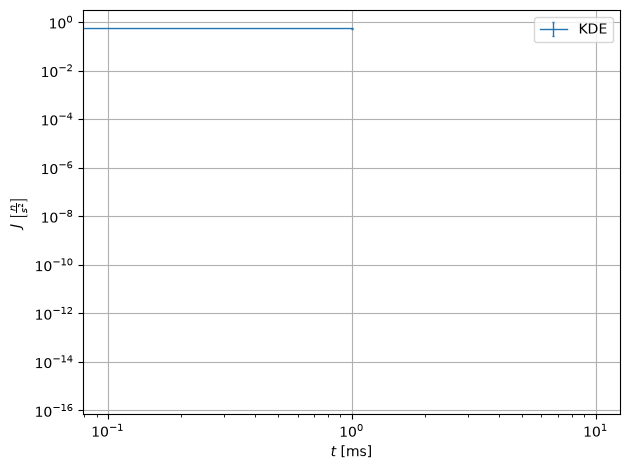

In [31]:
import numpy as np
my_source.plot_t(np.array([-1,0,1]))

In [41]:
my_source.kde.data

array([[ 2.50000003e-08,  6.70407397e-01, -5.64275606e-01, ...,
        -1.19058425e+00,  3.42558836e-01,  1.30924509e+00],
       [ 2.50000003e-08,  1.20174180e+00, -1.01641374e-01, ...,
        -9.86029887e-01, -1.33002217e+00,  7.12563121e-01],
       [ 2.50000003e-08,  4.35138113e-01,  3.86486287e-02, ...,
        -8.97095527e-01,  8.23024216e-01,  1.32921438e+00],
       ...,
       [ 2.50000003e-08,  1.27305014e+00,  9.84056009e-02, ...,
        -8.06618162e-01,  1.51619948e+00,  5.47235216e-01],
       [ 2.50000003e-08,  7.10821376e-01, -2.65878067e-01, ...,
        -1.09562543e+00,  1.16556383e+00,  8.30678022e-01],
       [ 2.50000003e-08,  7.35676016e-01,  1.67599095e+00, ...,
         8.64402083e-01,  1.18555943e+00,  1.04700429e+00]],
      shape=(10000, 8))

[<Figure size 640x480 with 1 Axes>,
 [array([0.92769468, 0.92769468, 0.92769468, 0.92769468]),
  array([0.00780095, 0.00780095, 0.00780095, 0.00780095])]]

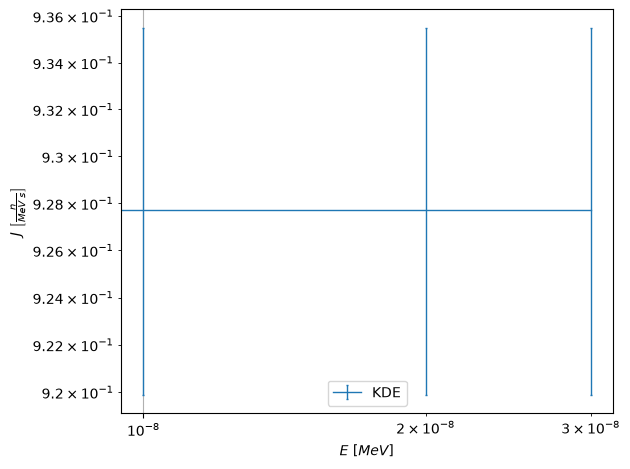

In [39]:
my_source.plot_E(grid_E=np.array([0,1e-8,2e-8,3e-8]))

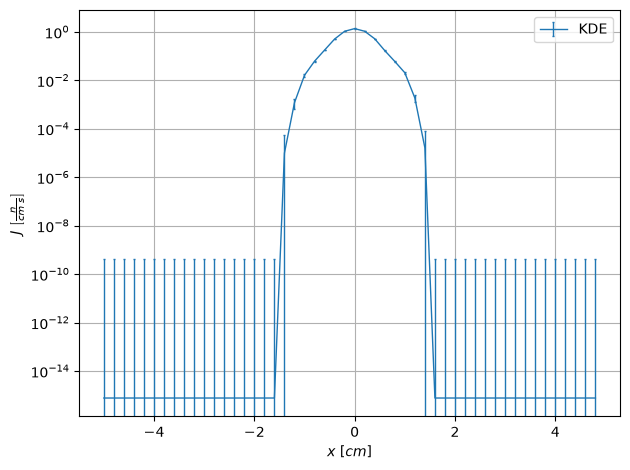

In [62]:
my_source.plot_integr(var="x", grid=np.arange(-5,5,0.2));

In [ ]:
my_source.save()

Successfully saved parameters file _source.xml


'_source.xml'

In [ ]:
kds.resample_to_mcpl("_source.xml", "generated_from_source.mcpl.gz", nout=100)

Reading xmlfile /home/jhonal/Brightify/_source.xml...
Done.
Resampling...
MCPL: Compressing file generated_from_source.mcpl
MCPL: Compressed file into generated_from_source.mcpl.gz
Successfully sampled 100 particles.


In [66]:
import mcpl
import pandas as pd

gen_file=mcpl.MCPLFile("generated_from_source.mcpl.gz")
datas = []
for i,p in enumerate(gen_file.particle_blocks):
    print("block no.", i)
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

block no. 0


,Kf,x,y,z,Vx,Vy,Vz,e,Wt
0,2112,-0.314750,0.087869,0.06,0.584076,0.630756,0.510883,0.452279,1.0
1,2112,-0.156093,0.229185,0.06,-0.096432,-0.959659,0.264113,0.659832,1.0
2,2112,-0.174374,0.424873,0.06,-0.459461,0.294224,0.838050,0.029960,1.0
3,2112,0.357392,-0.203787,0.06,-0.429220,0.178225,0.885441,0.347171,1.0
4,2112,0.375149,-0.023978,0.06,0.024622,0.518619,0.854651,0.051645,1.0
...,...,...,...,...,...,...,...,...,...
95,2112,-0.030924,-0.380031,0.06,-0.185489,0.388064,0.902774,0.001967,1.0
96,2112,-0.209845,-0.172571,0.06,-0.013932,-0.796015,0.605117,0.185403,1.0
97,2112,0.248228,0.310480,0.06,0.576967,-0.405146,0.709201,0.160421,1.0
98,2112,-0.219358,-0.501186,0.06,-0.605927,-0.767374,0.209737,0.046049,1.0


In [39]:
my_input_plist.N

21580959

In [21]:
kdsource.plist.pt2pdg?

Signature: kdsource.plist.pt2pdg(pt)
Docstring:
Convert particle type to pdgcode.

Valid particle types are:

    - 'n': neutron  (pdgcode = 2112)
    - 'p': photon   (pdgcode = 22)
    - 'e': electron (pdgcode = 11)

For other particle types, 0 is returned.

Parameters
----------
pt: str
    Particle type.
File:      ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/utils.py
Type:      function

In [1]:
import kdsource.api as kds
import mcpl
import pandas as pd
from pathlib import Path
import tempfile


def read_data(file_path, n=-1):
    blocklength = 10000
    gen_file = mcpl.MCPLFile(file_path, blocklength=blocklength)
    datas = []
    for i, p in enumerate(gen_file.particle_blocks):
        data = pd.DataFrame(
            {
                "Kf": p.pdgcode,  # Particle PDG code
                "x": p.x,  # x-position
                "y": p.y,  # y-position
                "z": p.z,  # z-position
                "Vx": p.ux,  # Velocity in x-direction
                "Vy": p.uy,  # Velocity in y-direction
                "Vz": p.uz,  # Velocity in z-direction
                "e": p.ekin,  # Kinetic energy
                "Wt": p.weight,  # Weight of the particle
            }
        )
        datas.append(data)
        if n != -1 and (i + 1) * blocklength >= n:
            break
    data = pd.concat(datas, ignore_index=True)
    if n != -1 and len(data) > n:
        data = data[:n]
    return data


def generate_data(
    inputFile,
    output_path=None,
    overwrite_output=False,
    n_gen=1_000,
    pt="n",
    n_fit=-1,
    kernel="gaussian",
    bw="silv",
    pCurrent=1.0,
    model_path=None,
    overwrite_model=False,
    generator=False,
):
    """
    Generates data similar to inputFile using kdsource, which uses KDE (Kernel Density Estimation) modeling.

    Parameters
    ---
    - inputFile: file path to input data; requires ending `.mcpl` or `.mcpl.gz`
    - output_path: file path for generated data (optional, see "Returns" section); file ending will be `.mcpl.gz`
    - overwrite_output: whether already existing file at output_path may be overwritten
    - n_gen: amount of particles to generate
    - pt: particle type ("n", "p", or "e") of generated particles and of input particles used for fitting the KDE model
    - n_fit: amount of input particles (with type `pt`) used for fitting of the source model (-1 means all)
    - kernel: kernel shape ("gaussian", "box", or "epa" (Epanechnikov))
    - bw: method for finding kernel bandwidth ("silv", "knn" or "mlcv")
    - pCurrent: total source particle current
    - model_path: where to save the model xml file (None makes it temporary)
    - overwrite_model: whether already existing file at model_path may be overwritten
    - generator: whether you want a generator for dataframes instead of one dataframe. `n_gen` will be the amount per yield.

    Returns
    ---
    - If output_path is specified: None. (The data will be saved to the file.)
    - If output_path is None: Pandas dataframe. Or, if `generator` is True: Generator of pandas dataframes.
    """

    inputFile = str(Path(inputFile).absolute())

    return_a_df = False
    output_is_temp = False
    model_is_temp = False

    if output_path is not None:
        output_path = Path(output_path).absolute().with_suffix(".mcpl.gz")
        if output_path.exists() and not overwrite_output:
            raise ValueError(
                "Output file already exists and overwriting is not allowed"
            )
        output_path = str(output_path)
    else:
        return_a_df = True
        output_path = str(Path(tempfile.gettempdir()) / "brightify_kdsource.mcpl.gz")
        output_is_temp = True

    if model_path is not None:
        model_path = Path(model_path).absolute().with_suffix(".xml")
        if model_path.exists() and not overwrite_model:
            raise ValueError("Model file already exists and overwriting is not allowed")
        model_path = str(model_path)
    else:
        model_path = str(Path(tempfile.gettempdir()) / "brightify_kdsource.xml")
        model_is_temp = True

    my_input_plist = kds.PList(
        filename=inputFile,
        readformat="mcpl",
        pt=pt,
        trasl=None,
        rot=None,
        switch_x2z=False,
        set_params=True,
    )
    # print(vars(my_input_plist))

    my_energy = kds.geom.Energy()
    my_time = kds.geom.Time()
    my_position = kds.geom.Vol()
    my_directions = kds.geom.Isotrop()
    my_geometry = kds.Geometry([my_energy, my_time, my_position, my_directions])
    # print(vars(my_geometry))

    my_source = kds.KDSource(
        plist=my_input_plist, geom=my_geometry, bw=bw, J=pCurrent, kernel=kernel
    )
    # print(vars(my_source))

    if n_fit == -1 or n_fit > my_input_plist.N:
        n_fit = my_input_plist.N
    # print("Amount of particles for fitting:", n_fit)

    my_source.fit(N=n_fit)

    model_path = str(Path(my_source.save(xmlfilename=model_path)).absolute())
    # if not model_is_temp:
    #     print("Source model saved to", model_path)
    # else:
    #     print("Temporary source model saved to", model_path)

    def resample_df(
        source,
        dest,
        nout,
        rng=None,
        force=False,
        no_df=False,
        del_dest=False,
        del_source=False,
    ):
        """
        Generates data at `dest` and by default returns it as a pandas dataframe.
        - source: source model .xml file (which contains the original data path that is required for sampling)
        - dest: a file path with .mcpl.gz ending
        - nout: amount of particles generated
        - rng: rng parameter
        - force: whether `dest` file may be overwritten if it already exists
        - no_df: whether you do NOT want to receive a dataframe for some reason
        - del_dest: whether to delete file at `dest` in the end
        - del_source: whether or not to delete the source .xml file in the end

        Returns
        - pandas dataframe, or `dest`, or None
        """
        # print("Amount of particles to generate:", str(nout))
        kds.resample_to_mcpl(
            kds_sourcefile=source,
            destination_mcpl=dest,
            nout=nout,
            rng=rng,
            force=force,
        )
        # print("Data generated at", dest)
        if not no_df:
            data = read_data(dest)
        if del_dest:
            Path(dest).unlink()
        if del_source:
            Path(source).unlink()
        if not no_df:
            return data
        if not del_dest:
            return dest
        return None

    def resample_df_gen(source, dest, nout, rng=None, del_dest=False, del_source=False):
        """
        A generator for dataframes via the resample method using an intermediate mcpl.gz file at `dest`. ATTENTION: Overwrites `dest` in each iteration!
        - source: source model .xml file (which contains the original data path that is required for sampling)
        - dest: a file path with .mcpl.gz ending
        - nout: amount of particles per dataframe
        - rng: If you specify it, it will be used for all the generated data. If None, uses new random rng for each iteration.
        - del_dest: whether or not to delete the most recent intermediate mcpl.gz file on the disk
        - del_source: whether or not to delete the source .xml file in the end (after the generator has stopped)
        """
        try:
            while True:
                yield resample_df(
                    source=source,
                    dest=dest,
                    nout=nout,
                    rng=rng,
                    force=True,
                    no_df=False,
                    del_dest=del_dest,
                    del_source=False,
                )
        finally:
            if del_source:
                Path(source).unlink()

    if not return_a_df:
        kds.resample_to_mcpl(
            kds_sourcefile=model_path,
            destination_mcpl=output_path,
            nout=n_gen,
            rng=None,
            force=True,
        )
        if model_is_temp:
            Path(model_path).unlink()
        return output_path
    else:
        if not generator:
            return resample_df(
                source=model_path,
                dest=output_path,
                nout=n_gen,
                rng=None,
                force=True,
                no_df=False,
                del_dest=output_is_temp,
                del_source=model_is_temp,
            )
        else:
            return resample_df_gen(
                source=model_path,
                dest=output_path,
                nout=n_gen,
                rng=None,
                del_dest=output_is_temp,
                del_source=model_is_temp,
            )

In [2]:
example_path = "./examples/uniform/output.mcpl.gz"

In [3]:
data1 = generate_data(inputFile=example_path, n_gen=100_000, n_fit=1_000_000, bw="silv")

Using existing file /home/jhonal/Brightify/examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
Using 1000000 particles for fit.
Calculating bw ... 
Done
Optimal bw (silv) = [[2.92980241e-01 2.66444839e-04 8.49627993e-02 8.50051009e-02
  5.45238477e-10 1.62146410e-01 1.62146410e-01 1.62146410e-01]]
Successfully saved parameters file /tmp/brightify_kdsource.xml
Reading xmlfile /tmp/brightify_kdsource.xml...
Done.
Resampling...
MCPL: Compressing file brightify_kdsource.mcpl
MCPL: Compressed file into brightify_kdsource.mcpl.gz
Successfully sampled 100000 particles.


In [4]:
data2 = read_data(example_path, 100_000)

In [5]:
gen = generate_data(
    inputFile=example_path,
    output_path=None,
    overwrite_output=False,
    n_gen=100,
    pt="n",
    n_fit=100_000,
    kernel="gaussian",
    bw="silv",
    pCurrent=1.0,
    model_path=None,
    overwrite_model=False,
    generator=True,
)

Using existing file /home/jhonal/Brightify/examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
Using 100000 particles for fit.
Calculating bw ... 
Done
Optimal bw (silv) = [[3.54953666e-01 3.22447490e-04 1.03094212e-01 1.03211731e-01
  6.60560402e-10 1.96524623e-01 1.96524623e-01 1.96524623e-01]]
Successfully saved parameters file /tmp/brightify_kdsource.xml


In [6]:
data3=next(gen)

Reading xmlfile /tmp/brightify_kdsource.xml...
Done.
Resampling...
MCPL: Compressing file brightify_kdsource.mcpl
MCPL: Compressed file into brightify_kdsource.mcpl.gz
Successfully sampled 100 particles.


In [7]:
gen.close()

In [8]:
data3=next(gen)

StopIteration: 

In [9]:
import numpy as np

In [10]:
for d in [data1, data2, data3]:
    d["V_norm"] = np.sqrt((d.Vx*d.Vx + d.Vy*d.Vy + d.Vz+d.Vz))

In [11]:
data1.describe()

,Kf,x,y,z,Vx,Vy,Vz,e,Wt,V_norm
count,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.0,100000.000000
mean,2112.0,-0.000306,0.000004,6.000000e-02,-0.000111,-0.001082,0.531401,1.814021e-01,1.0,1.299371
std,0.0,0.297690,0.298626,1.861089e-09,0.564975,0.565680,0.280051,1.374070e-01,0.0,0.116714
min,2112.0,-1.176760,-1.172776,5.999999e-02,-0.999969,-0.999942,-0.344930,7.835729e-07,1.0,0.437222
25%,2112.0,-0.187070,-0.187049,6.000000e-02,-0.488784,-0.489572,0.307956,7.241993e-02,1.0,1.233319
50%,2112.0,-0.000293,0.000423,6.000000e-02,-0.000025,0.000845,0.540313,1.523588e-01,1.0,1.337419
75%,2112.0,0.185556,0.187078,6.000000e-02,0.488268,0.486540,0.771231,2.614549e-01,1.0,1.395588
max,2112.0,1.144220,1.127604,6.000000e-02,0.999997,0.999947,0.999996,1.047240e+00,1.0,1.414214


In [12]:
data2.describe()

,Kf,x,y,z,Vx,Vy,Vz,e,Wt,V_norm
count,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.0,100000.000000
mean,2112.0,-0.000097,0.000075,6.000000e-02,-0.000182,-0.001473,0.540184,2.500000e-08,1.0,1.306939
std,0.0,0.290446,0.290777,1.860986e-09,0.564340,0.564941,0.265646,0.000000e+00,0.0,0.099559
min,2112.0,-0.999378,-0.999558,6.000000e-02,-0.998071,-0.998391,0.040059,2.500000e-08,1.0,1.038515
25%,2112.0,-0.181128,-0.180439,6.000000e-02,-0.488638,-0.490028,0.310469,2.500000e-08,1.0,1.234726
50%,2112.0,-0.000122,0.000144,6.000000e-02,0.000303,-0.003172,0.540990,2.500000e-08,1.0,1.337651
75%,2112.0,0.180522,0.180300,6.000000e-02,0.487022,0.485866,0.768877,2.500000e-08,1.0,1.395200
max,2112.0,0.999718,0.998951,6.000000e-02,0.998140,0.998069,0.999998,2.500000e-08,1.0,1.414214


In [13]:
data3.describe()

,Kf,x,y,z,Vx,Vy,Vz,e,Wt,V_norm
count,100.0,100.000000,100.000000,1.000000e+02,100.000000,100.000000,100.000000,100.000000,100.0,100.000000
mean,2112.0,-0.027324,0.010560,6.000000e-02,-0.074254,0.065426,0.552566,0.164362,1.0,1.304110
std,0.0,0.278640,0.285440,1.853592e-09,0.529176,0.571329,0.292147,0.133836,0.0,0.121453
min,2112.0,-0.786499,-0.602196,6.000000e-02,-0.997333,-0.961036,-0.077601,0.000087,1.0,0.915847
25%,2112.0,-0.223402,-0.182227,6.000000e-02,-0.477861,-0.452615,0.324127,0.066735,1.0,1.242254
50%,2112.0,-0.034543,-0.011118,6.000000e-02,-0.124570,0.141368,0.575746,0.126789,1.0,1.349075
75%,2112.0,0.151269,0.185933,6.000000e-02,0.315408,0.544067,0.814500,0.234861,1.0,1.401995
max,2112.0,0.693980,0.824122,6.000000e-02,0.847555,0.996647,0.992647,0.579284,1.0,1.414194


In [37]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_data_row(datas, rows=["x", "Vx", "e", "Wt"]):
    colors = list(mcolors.TABLEAU_COLORS.values())
    for j, row in enumerate(rows):
        color = colors[j]
        for i, data in enumerate(datas):
            plt.hist(data[row], density=True, bins=20, histtype="step", label=row+" "+str(i), color=color, linestyle=(0,(i%2+1,i*2+1)))
    plt.legend()
    plt.show()


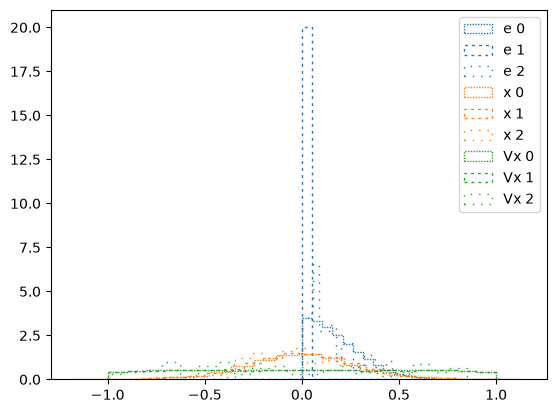

In [40]:
plot_data_row(datas=[data1, data2, data3], rows=["e", "x", "Vx"])